In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from matplotlib.ticker import ScalarFormatter

In [2]:
# Grid and differential operators

def make_grid(x_min, x_max, delta_x, Cx):
    dx = Cx * delta_x
    x1 = np.arange(x_min, x_max + 0.5 * dx, dx)
    x2 = np.arange(x_min, x_max + 0.5 * dx, dx)
    X1, X2 = np.meshgrid(x1, x2, indexing="ij")
    return x1, x2, X1, X2, dx, dx, dx

def grad2(F, dx, dy):
    return (
        np.gradient(F, dx, axis=0, edge_order=2),
        np.gradient(F, dy, axis=1, edge_order=2),
    )

def lap2(F, dx, dy):
    Fx, Fy = grad2(F, dx, dy)
    return (
        np.gradient(Fx, dx, axis=0, edge_order=2)
        + np.gradient(Fy, dy, axis=1, edge_order=2)
    )

def A_of_F(rho, F, dx, dy):
    rx, ry = grad2(rho, dx, dy)
    Fx, Fy = grad2(F, dx, dy)
    return rx * Fx + ry * Fy + rho * lap2(F, dx, dy)

# Godunov Hamiltonian
def one_sided_diffs(F, dx, dy):
    Dxm = np.zeros_like(F)
    Dxp = np.zeros_like(F)
    Dym = np.zeros_like(F)
    Dyp = np.zeros_like(F)
    Dxm[1:] = (F[1:] - F[:-1]) / dx
    Dxm[0] = Dxm[1]
    Dxp[:-1] = (F[1:] - F[:-1]) / dx
    Dxp[-1] = Dxp[-2]
    Dym[:,1:] = (F[:,1:] - F[:,:-1]) / dy
    Dym[:,0] = Dym[:,1]
    Dyp[:,:-1] = (F[:,1:] - F[:,:-1]) / dy
    Dyp[:,-1] = Dyp[:,-2]
    return Dxm, Dxp, Dym, Dyp

def godunov_square(Dm, Dp):
    out = np.zeros_like(Dm)
    rare = Dm <= Dp
    out[rare & (Dm > 0)] = np.minimum(Dm[rare & (Dm > 0)]**2, Dp[rare & (Dm > 0)]**2)
    out[rare & (Dp < 0)] = np.minimum(Dm[rare & (Dp < 0)]**2, Dp[rare & (Dp < 0)]**2)
    out[rare & (Dm <= 0) & (Dp >= 0)] = 0.0
    out[~rare] = np.maximum(Dm[~rare]**2, Dp[~rare]**2)
    return out

def H_godunov(phi, dx, dy):
    Dxm, Dxp, Dym, Dyp = one_sided_diffs(phi, dx, dy)
    return (0.5 * godunov_square(Dxm, Dxp)+ 0.5 * godunov_square(Dym, Dyp))

# Time stepping
def Uprime(rho, m, kappa):
    return kappa * m / (m - 1) * rho**(m - 1)

def update_phi(phi, rho, V, dt, dx, dy, m, kappa, gauge=True):
    phi_new = phi - dt * ( H_godunov(phi, dx, dy) + Uprime(rho, m, kappa) + V)
    if gauge:
        phi_new -= np.mean(phi_new)
    return phi_new

def update_rho(rho, phi, dt, dx, dy):
    vx, vy = grad2(phi, dx, dy)
    Nx, Ny = rho.shape
    Fx = np.zeros((Nx + 1, Ny))
    Fy = np.zeros((Nx, Ny + 1))
    vx_f = 0.5 * (vx[:-1] + vx[1:])
    vy_f = 0.5 * (vy[:, :-1] + vy[:, 1:])
    Fx[1:-1] = np.where(vx_f > 0, vx_f * rho[:-1], vx_f * rho[1:])
    Fy[:,1:-1] = np.where(vy_f > 0, vy_f * rho[:,:-1], vy_f * rho[:,1:])
    div = ((Fx[1:] - Fx[:-1]) / dx + (Fy[:,1:] - Fy[:,:-1]) / dy)
    rho_new = np.maximum(rho - dt * div, 0.0)
    rho_new /= rho_new.sum() * dx * dy
    return rho_new

# Plotting
def plot_field(x1, x2, F, title, label, save_name):
    plt.figure(figsize=(6,5))
    plt.contourf(x1, x2, F.T, levels=50, cmap="viridis")
    plt.colorbar(label=label)
    plt.xlabel(r"$x_1$")
    plt.ylabel(r"$x_2$")
    if title:
        plt.title(title)
    plt.axis("equal")
    plt.tight_layout()
    plt.savefig(save_name, dpi=300, bbox_inches="tight")
    plt.show()

def plot_mass(times, mass, save_name):
    plt.figure(figsize=(7,4))
    plt.plot(times, mass, lw=2)
    plt.xlabel(r"$t$")
    plt.ylabel("mass")
    plt.tight_layout()
    plt.savefig(save_name, dpi=300, bbox_inches="tight")
    plt.show()

def plot_rho_snapshots(x1, x2, rho, times, outdir, prefix="rho", nsnap=5):
    os.makedirs(outdir, exist_ok=True)
    ids = np.linspace(0, len(times)-1, nsnap, dtype=int)
    for k in ids:
        plot_field(x1, x2, rho[k], rf"$t={times[k]:.3f}$", r"$\rho$", f"{outdir}/{prefix}_{k:03d}.png")


def generate_whf_data(V_true, initial_rho_phi, V_name, T_final, delta_t, Ct, delta_x, Cx, x_min, x_max, save_name, m, kappa):
    x1, x2, X1, X2, dx, dy, Delta_x = make_grid(x_min, x_max, delta_x, Cx)
    rho, phi = initial_rho_phi(X1, X2, dx, dy)
    n_steps = int(round(T_final / delta_t))
    Delta_t = Ct * delta_t
    times = []
    rho_list = []
    phi_list = []
    for n in range(n_steps + 1):
        if n % Ct == 0:
            times.append(n * delta_t)
            rho_list.append(rho.copy())
            phi_list.append(phi.copy())
        if n == n_steps:
            break
        phi = update_phi(phi, rho, V_true, delta_t, dx, dy, m, kappa)
        rho = update_rho(rho, phi, delta_t, dx, dy)
    times = np.asarray(times)
    rho = np.asarray(rho_list)
    phi = np.asarray(phi_list)
    A_phi = np.array([A_of_F(rho[l], phi[l], dx, dy) for l in range(len(times))])
    A_Vtrue = np.array([A_of_F(rho[l], V_true, dx, dy) for l in range(len(times))])
    Hgod = np.array([H_godunov(phi[l], dx, dy) for l in range(len(times))])
    Uprime_arr = Uprime(rho, m, kappa)
    rho_t = -A_phi
    rho_tt = np.gradient(rho_t, Delta_t, axis=0, edge_order=2)
    mass = rho.sum(axis=(1,2)) * dx * dy
    print("Saved:", save_name)
    print("rho shape =", rho.shape)
    print("phi shape =", phi.shape)
    plot_mass(times, mass, f"figures/{V_name}_mass.png")
    plot_field(x1, x2, V_true, r"True potential", r"$V$", f"figures/{V_name}_V_true.png")
    plot_rho_snapshots(x1, x2, rho, times, outdir="figures", prefix=f"{V_name}_rho")

    np.savez_compressed(
        save_name,
        x1_obs=x1,
        x2_obs=x2,
        obs_times=times,
        rho=rho,
        phi=phi,
        H_god=Hgod,
        Uprime=Uprime_arr,
        rho_t=rho_t,
        rho_tt=rho_tt,
        V_true=V_true,
        A_Vtrue=A_Vtrue,
        mass=mass,
        dx=dx,
        dy=dy,
        dt=Delta_t,
        Cx=Cx,
        Ct=Ct,
        m=m,
        kappa=kappa,
    )

    print("Saved:", save_name)
    print("rho shape =", rho.shape)
    print("phi shape =", phi.shape)

    return dict(
        x1=x1,
        x2=x2,
        X1=X1,
        X2=X2,
        rho=rho,
        phi=phi,
        H_god=Hgod,
        Uprime=Uprime_arr,
        V_true=V_true,
        A_phi=A_phi,
        A_Vtrue=A_Vtrue,
        times=times,
        mass=mass,
    )

def check_whf_data(D):
    rho = D["rho"]
    phi = D["phi"]
    V = D["V_true"]
    H_god = D["H_god"]
    Uprime_arr = D["Uprime"] if "Uprime" in D else 0.0
    x1 = D["x1"] if "x1" in D else D["x1_obs"]
    x2 = D["x2"] if "x2" in D else D["x2_obs"]
    times = D["times"] if "times" in D else D["obs_times"]
    dx = x1[1] - x1[0]
    dy = x2[1] - x2[0]
    dt = times[1] - times[0]
    Nt = len(times)
    ids = np.arange(1, Nt - 1)
    rho_t = np.zeros_like(rho)
    phi_t = np.zeros_like(phi)
    rho_t[1:-1] = (rho[2:] - rho[:-2]) / (2 * dt)
    phi_t[1:-1] = (phi[2:] - phi[:-2]) / (2 * dt)
    A_phi = np.array([A_of_F(rho[l], phi[l], dx, dy) for l in range(Nt)])
    cont_res = rho_t[ids] + A_phi[ids]
    hj_res = (phi_t[ids] + H_god[ids] + Uprime_arr[ids] + V)
    hj_res -= np.mean(hj_res, axis=(1,2), keepdims=True)
    rel_cont = np.sqrt(
        np.sum(rho[ids] * cont_res**2)
        /
        np.sum(rho[ids] * rho_t[ids]**2)
    )
    rel_hj = np.sqrt(
        np.sum(rho[ids] * hj_res**2)
        /
        np.sum(rho[ids] * V**2)
    )
    mass = rho.sum(axis=(1,2)) * dx * dy
    print("mass min/max =", mass.min(), mass.max())
    print("relative continuity residual =", rel_cont)
    print("relative HJ residual =", rel_hj)
    return rel_cont, rel_hj

Saved: data/example3_whf_polynomial_Cx5_Ct50.npz
rho shape = (401, 201, 201)
phi shape = (401, 201, 201)


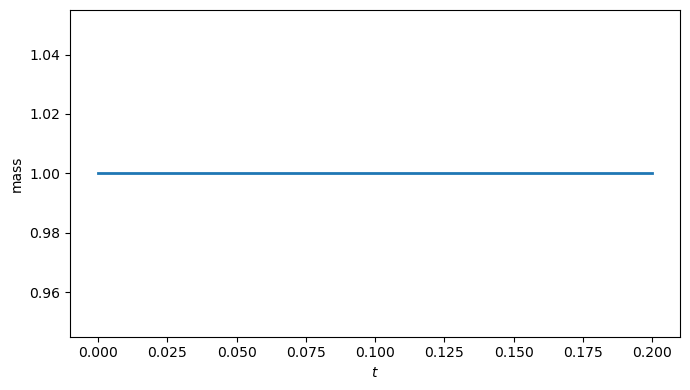

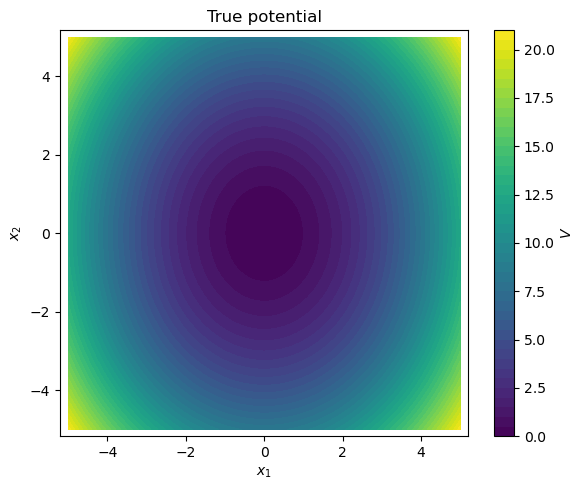

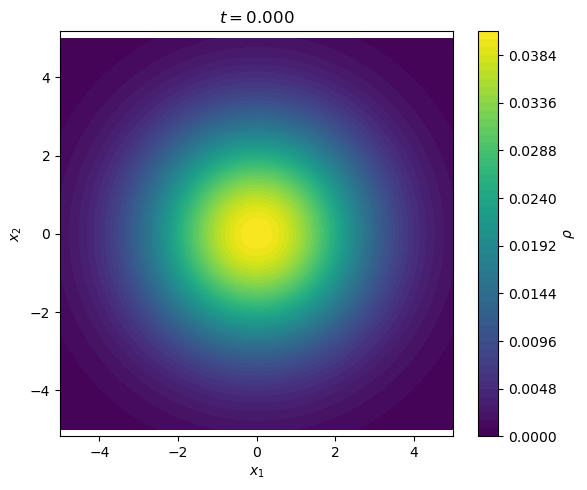

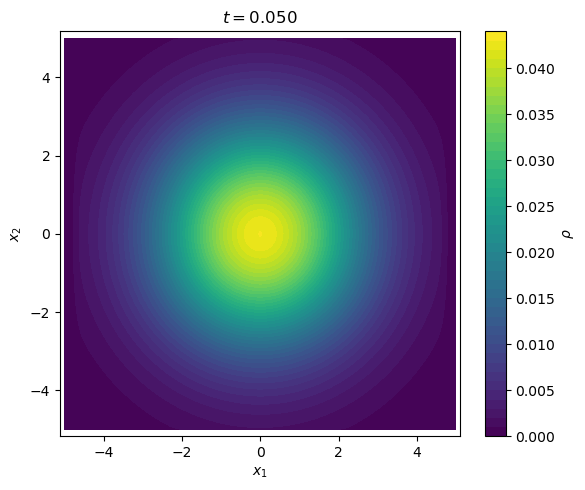

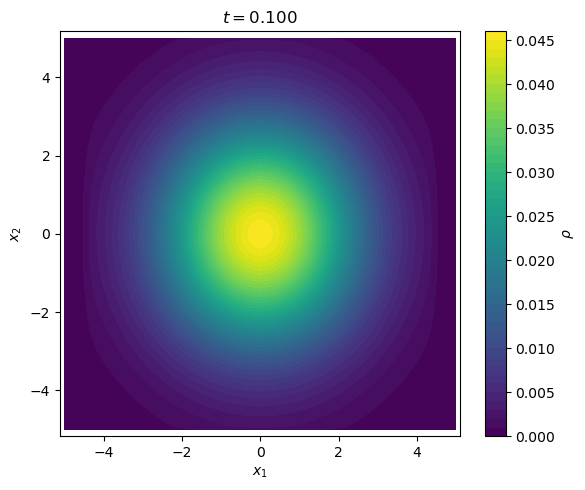

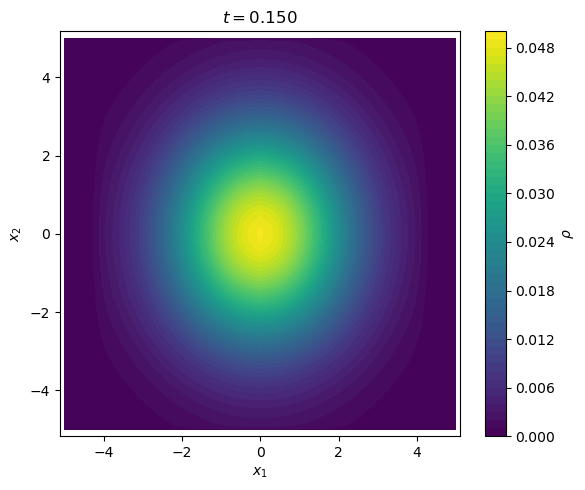

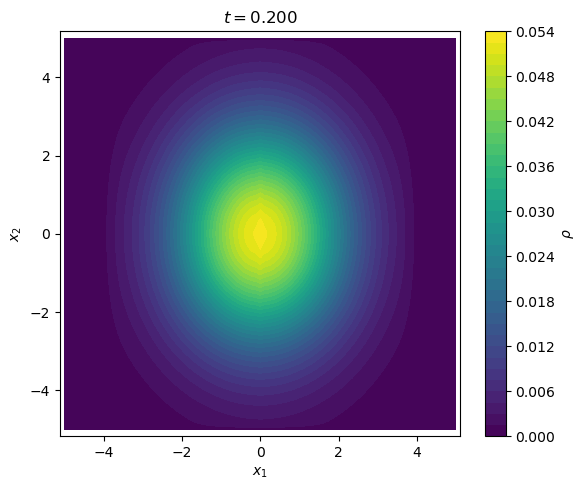

Saved: data/example3_whf_polynomial_Cx5_Ct50.npz
rho shape = (401, 201, 201)
phi shape = (401, 201, 201)
mass min/max = 0.9999999999999926 0.9999999999999932
relative continuity residual = 0.01800557278176856
relative HJ residual = 2.2565893772935767e-05


In [3]:
# Example 3: polynomial potential

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)
delta_x = 0.01
delta_t = 1e-5
Cx = 5
Ct = 50
T_final = 0.2
m = 2
kappa = 0.5
x_min, x_max = -5.0, 5.0
x1, x2, X1, X2, dx, dy, Delta_x = make_grid(x_min, x_max, delta_x, Cx)

V_name = "polynomial"
V_true = (0.5 * X1**2 + (1.0/3.0) * X2**2)

def initial_rho_phi(X1, X2, dx, dy):
    rho = np.exp(-0.125 * (X1**2 + X2**2)) / (8.0 * np.pi)
    rho /= rho.sum() * dx * dy
    phi = -0.5 * X1**2
    return rho, phi

D = generate_whf_data(
    V_true=V_true,
    initial_rho_phi=initial_rho_phi,
    V_name=V_name,
    T_final=T_final,
    delta_t=delta_t,
    Ct=Ct,
    delta_x=delta_x,
    Cx=Cx,
    x_min=x_min,
    x_max=x_max,
    save_name=f"data/example3_whf_{V_name}_Cx{Cx}_Ct{Ct}.npz",
    m=m,
    kappa=kappa,
)

C = check_whf_data(D)

Saved: data/example4_whf_highly_nonconvex_Cx5_Ct50.npz
rho shape = (401, 201, 201)
phi shape = (401, 201, 201)


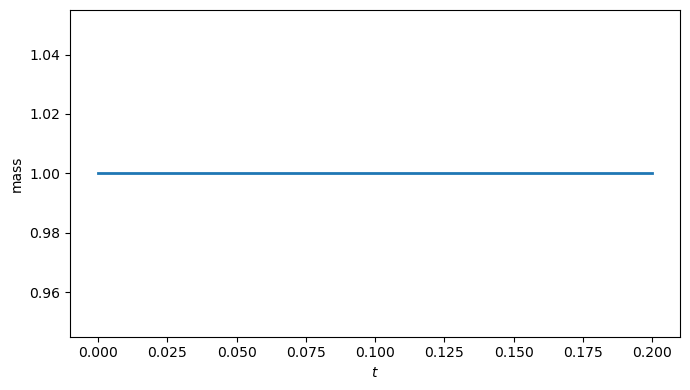

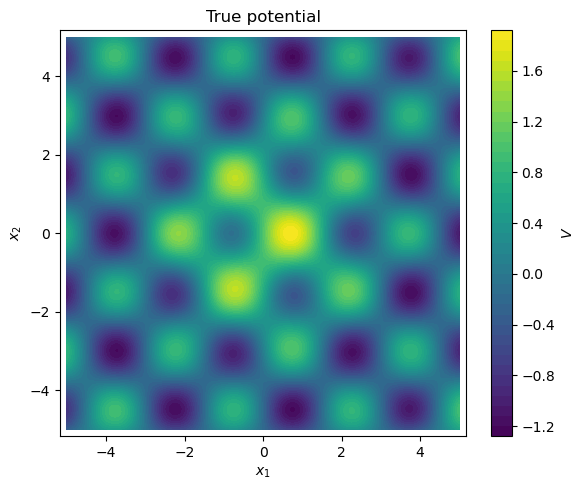

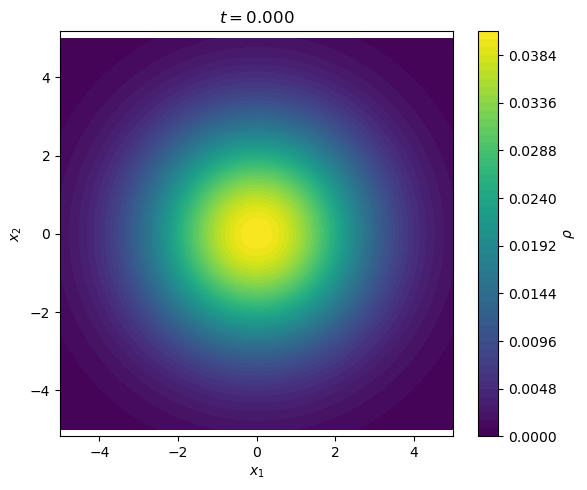

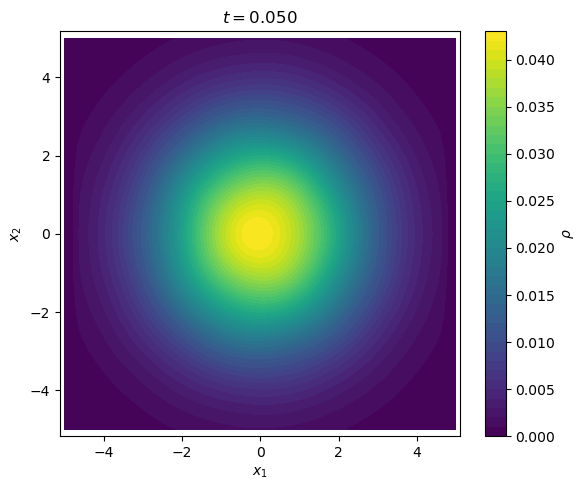

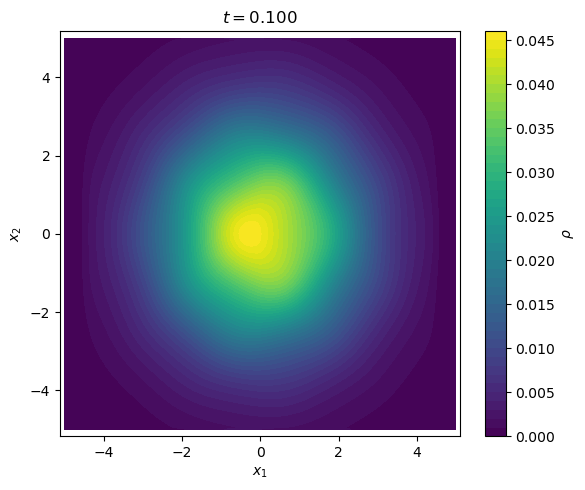

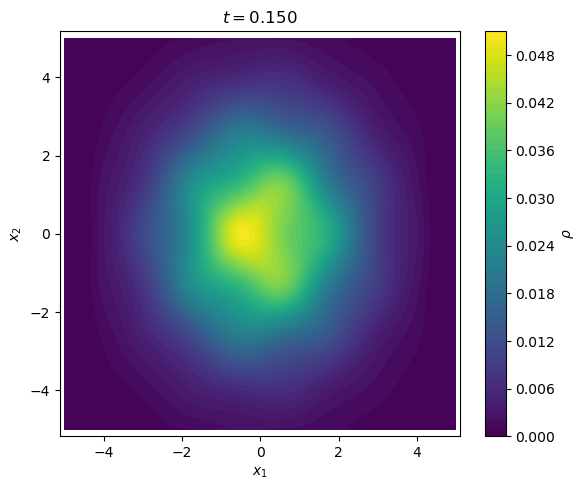

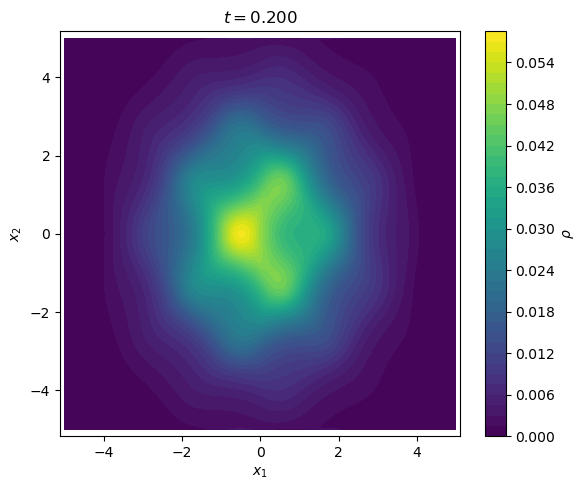

Saved: data/example4_whf_highly_nonconvex_Cx5_Ct50.npz
rho shape = (401, 201, 201)
phi shape = (401, 201, 201)
mass min/max = 0.9999999999999926 0.9999999999999932
relative continuity residual = 0.02082547977300692
relative HJ residual = 4.87455746912608e-05


In [4]:
# Example 4: highly_nonconvex potential

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)
delta_x = 0.01
delta_t = 1e-5
Cx = 5
Ct = 50
T_final = 0.2
m = 3
kappa = 1
x_min, x_max = -5.0, 5.0
x1, x2, X1, X2, dx, dy, Delta_x = make_grid(x_min, x_max, delta_x,Cx)

V_name = "highly_nonconvex"
r = np.sqrt(X1**2 + X2**2)
V_true = (np.sin(2.0 * np.pi * X1 / 3.0) * np.cos(2.0 * np.pi * X2 / 3.0) + np.sinc(r / np.pi))
def initial_rho_phi(X1, X2, dx, dy):
    rho = np.exp(-0.125 * (X1**2 + X2**2)) / (8.0 * np.pi)
    rho /= rho.sum() * dx * dy
    phi = -0.5 * X1**2
    return rho, phi

D = generate_whf_data(
    V_true=V_true,
    initial_rho_phi=initial_rho_phi,
    V_name=V_name,
    T_final=T_final,
    delta_t=delta_t,
    Ct=Ct,
    delta_x=delta_x,
    Cx=Cx,
    x_min=x_min,
    x_max=x_max,
    save_name=f"data/example4_whf_{V_name}_Cx{Cx}_Ct{Ct}.npz",
    m=m,
    kappa=kappa,
)

C = check_whf_data(D)